<a href="https://colab.research.google.com/github/rexarsh/online-retail-data-analysis/blob/main/onlineretail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print("Total rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Total rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 5268


In [ ]:
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Total cancelled rows:", len(cancelled))

display(cancelled.head())

Total cancelled rows: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [ ]:
#creating a copy of the original dataset
cleaned_df = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", cleaned_df.shape)

Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


In [ ]:
#checking missing values in the dataset
print("Missing values before cleaning:")
print(cleaned_df.isnull().sum())

#removing rows where customer id is missing
cleaned_df = cleaned_df.dropna(subset=["CustomerID"])

#checking missing values after cleaning
print("\nMissing values after cleaning:")
print(cleaned_df.isnull().sum())

print("\nDataset shape after cleaning:", cleaned_df.shape)

Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Dataset shape after cleaning: (406829, 8)


In [ ]:
#checking missing customer ids before removing them
print("Missing customer IDs:", df["CustomerID"].isnull().sum())

#creating a dataset for customer analysis
customer_df = df.dropna(subset=["CustomerID"]).copy()

print("Dataset shape for customer analysis:", customer_df.shape)

Missing customer IDs: 135080
Dataset shape for customer analysis: (406829, 8)


In [ ]:
#checking duplicate rows in the dataset
print("Duplicate rows before cleaning:", customer_df.duplicated().sum())

#removing duplicate rows
customer_df = customer_df.drop_duplicates()

#checking duplicate rows after cleaning
print("Duplicate rows after cleaning:", customer_df.duplicated().sum())

print("Dataset shape after removing duplicates:", customer_df.shape)

Duplicate rows before cleaning: 5225
Duplicate rows after cleaning: 0
Dataset shape after removing duplicates: (401604, 8)


In [ ]:
#checking cancelled transactions
cancelled_rows = customer_df[
    customer_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Cancelled transactions:", len(cancelled_rows))

#removing cancelled transactions from the sales dataset
customer_df = customer_df[
    ~customer_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Cancelled transactions removed:", len(cancelled_rows))
print("Dataset shape after removing cancellations:", customer_df.shape)

Cancelled transactions: 8872
Cancelled transactions removed: 8872
Dataset shape after removing cancellations: (392732, 8)


In [ ]:
#checking invalid quantities and prices
print("Zero or negative quantities:",
      (customer_df["Quantity"] <= 0).sum())

print("Zero or negative prices:",
      (customer_df["UnitPrice"] <= 0).sum())

Zero or negative quantities: 0
Zero or negative prices: 40


In [ ]:
#checking rows with invalid prices
invalid_prices = customer_df[customer_df["UnitPrice"] <= 0]

print("Rows with invalid prices:", len(invalid_prices))

display(invalid_prices.head(10))

Rows with invalid prices: 40


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [ ]:
#checking zero price transactions
zero_price_rows = customer_df[customer_df["UnitPrice"] == 0].copy()

print("Zero price rows:", len(zero_price_rows))

#removing zero price rows from the sales dataset
customer_df = customer_df[customer_df["UnitPrice"] > 0].copy()

print("Dataset shape after cleaning:", customer_df.shape)

#checking invalid prices again
print("Invalid prices remaining:",
      (customer_df["UnitPrice"] <= 0).sum())

Zero price rows: 40
Dataset shape after cleaning: (392692, 8)
Invalid prices remaining: 0


In [ ]:
#checking the final cleaned dataset
print("Final dataset shape:", customer_df.shape)

print("\nMissing values:")
print(customer_df.isnull().sum())

print("\nDuplicate rows:", customer_df.duplicated().sum())

print("\nCancelled invoices:",
      customer_df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("\nInvalid quantities:",
      (customer_df["Quantity"] <= 0).sum())

print("\nInvalid prices:",
      (customer_df["UnitPrice"] <= 0).sum())

Final dataset shape: (392692, 8)

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate rows: 0

Cancelled invoices: 0

Invalid quantities: 0

Invalid prices: 0


In [ ]:
#saving the cleaned dataset
customer_df.to_csv("online_retail_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
#calculating total revenue
customer_df["Revenue"] = customer_df["Quantity"] * customer_df["UnitPrice"]

print("Revenue calculated successfully!")

display(customer_df.head())

Revenue calculated successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [ ]:
#extracting year and month from invoice date
customer_df["Month"] = pd.to_datetime(customer_df["InvoiceDate"]).dt.strftime("%Y-%m")

#calculating monthly revenue
monthly_revenue = customer_df.groupby("Month")["Revenue"].sum()

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Name: Revenue, dtype: float64


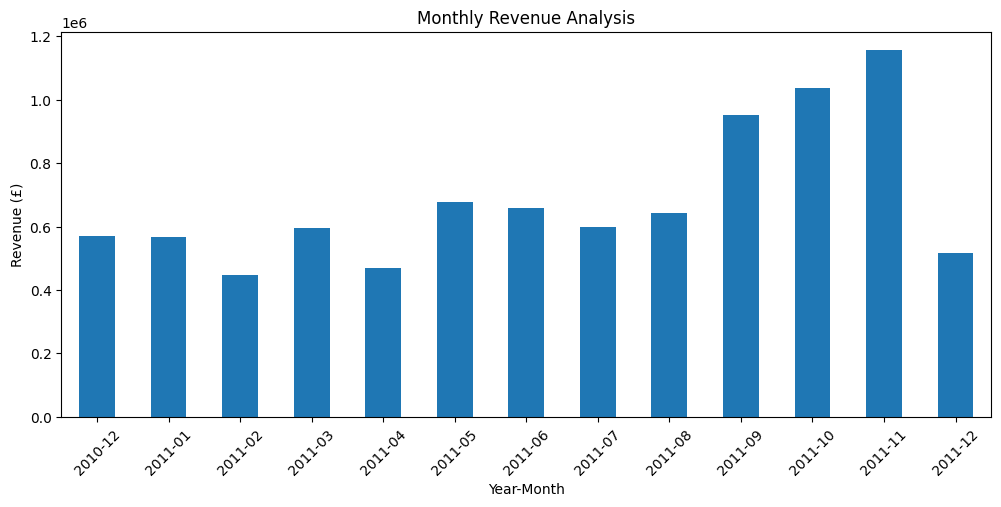

In [ ]:
#plotting monthly revenue
plt.figure(figsize=(12,5))

monthly_revenue.plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#finding top 10 selling products
top_products = customer_df.groupby("Description")["Quantity"].sum()

top_products = top_products.sort_values(ascending=False).head(10)

print("Top 10 Selling Products:")
print(top_products)

Top 10 Selling Products:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


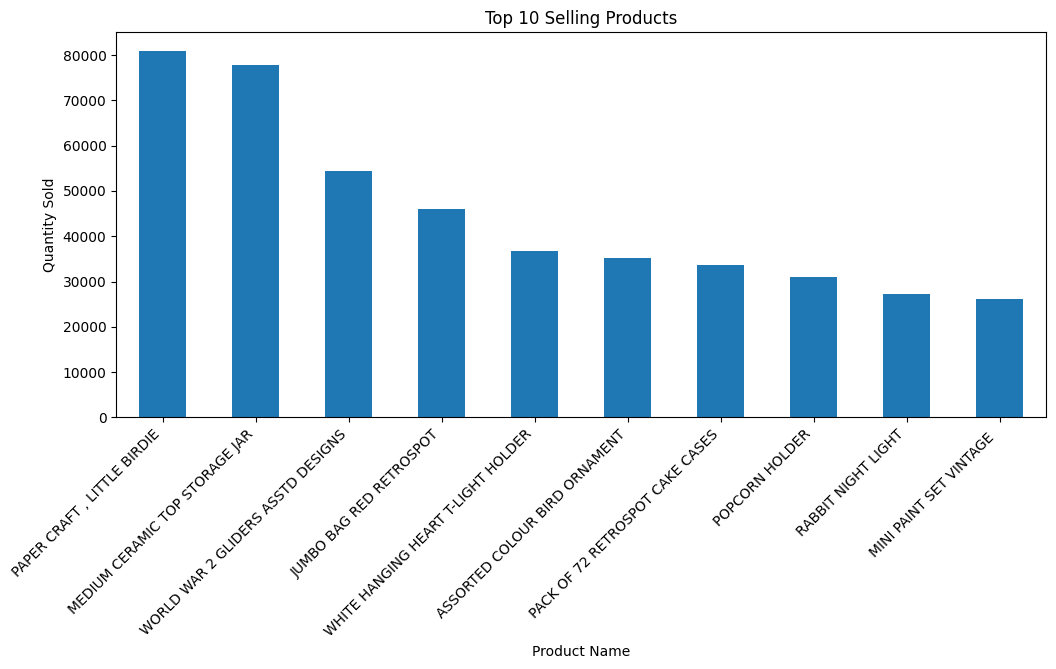

In [ ]:
#plotting top 10 selling products
plt.figure(figsize=(12,5))

top_products.plot(kind="bar")

plt.title("Top 10 Selling Products")
plt.xlabel("Product Name")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45, ha="right")

plt.show()

In [ ]:
#calculating purchase frequency of customers
purchase_frequency = customer_df.groupby("CustomerID")["InvoiceNo"].nunique()

print("Purchase Frequency:")
print(purchase_frequency.head(10))

Purchase Frequency:
CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
12352.0    8
12353.0    1
12354.0    1
12355.0    1
12356.0    3
Name: InvoiceNo, dtype: int64


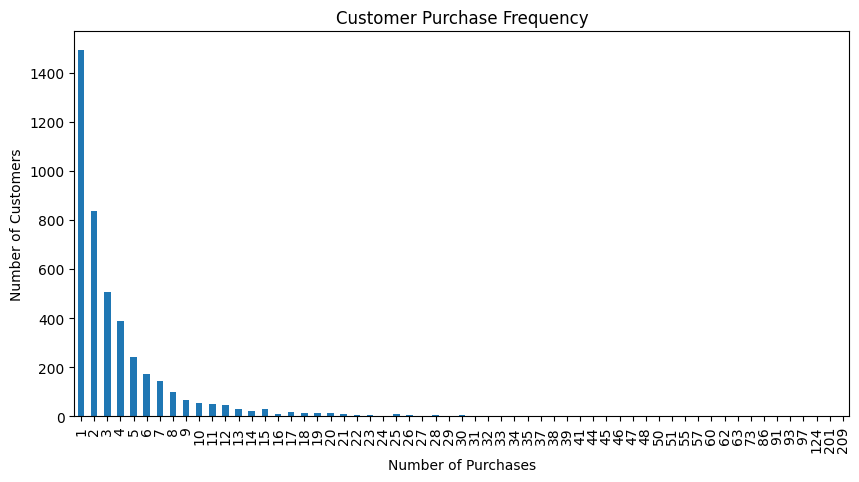

In [ ]:
#plotting purchase frequency
plt.figure(figsize=(10,5))

purchase_frequency.value_counts().sort_index().plot(kind="bar")

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
#calculating revenue by country
country_revenue = customer_df.groupby("Country")["Revenue"].sum()

#sorting countries by revenue
country_revenue = country_revenue.sort_values(ascending=False)

print("Revenue by Country:")
print(country_revenue.head(10))

Revenue by Country:
Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


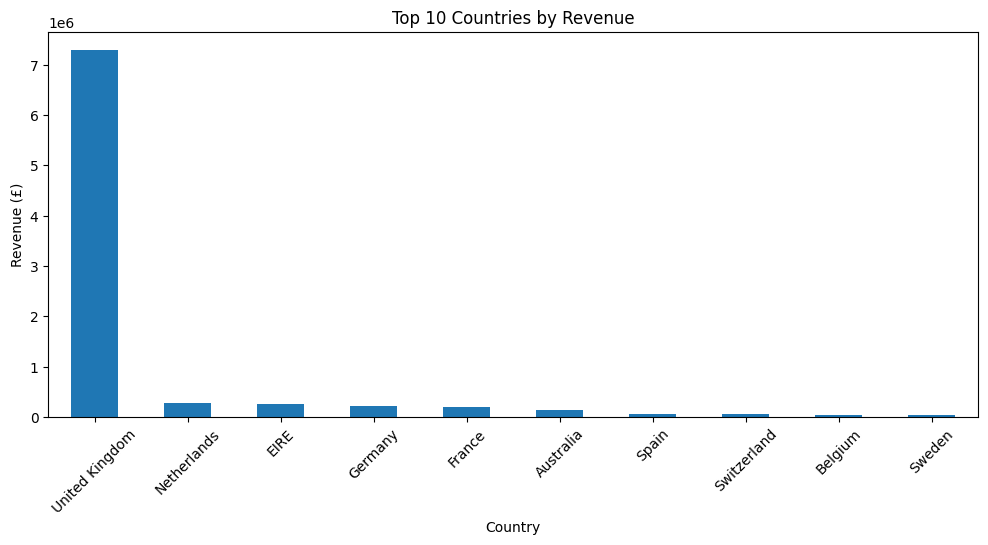

In [ ]:
#plotting revenue by country
plt.figure(figsize=(12,5))

country_revenue.head(10).plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#calculating rfm values for each customer

reference_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

#renaming the columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

print("RFM analysis completed!")

display(rfm.head(10))

RFM analysis completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [ ]:
#checking rfm data summary
print("RFM Data Summary:")
display(rfm.describe())

RFM Data Summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [ ]:
#assigning rfm scores to customers

rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1])

rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4])

rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4])

#calculating total rfm score
rfm["RFM_Score"] = rfm["R_Score"].astype(int) + rfm["F_Score"].astype(int) + rfm["M_Score"].astype(int)

print("RFM scores assigned successfully!")

display(rfm.head(10))

RFM scores assigned successfully!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,6
12347.0,2,7,4310.00,4,4,4,12
12348.0,75,4,1797.24,2,3,4,9
12349.0,19,1,1757.55,3,1,4,8
12350.0,310,1,334.40,1,1,2,4
12352.0,36,8,2506.04,3,4,4,11
12353.0,204,1,89.00,1,1,1,3
12354.0,232,1,1079.40,1,1,3,5
12355.0,214,1,459.40,1,1,2,4


In [ ]:
#creating customer segments
rfm["Segment"] = "Occasional"

rfm.loc[rfm["RFM_Score"] >= 8, "Segment"] = "Loyal"

rfm.loc[rfm["RFM_Score"] >= 10, "Segment"] = "High-Value"

rfm.loc[rfm["RFM_Score"] <= 4, "Segment"] = "Inactive"

print("Customer segmentation completed!")

display(rfm.head(10))


Customer segmentation completed!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,4,6,Occasional
12347.0,2,7,4310.00,4,4,4,12,High-Value
12348.0,75,4,1797.24,2,3,4,9,Loyal
12349.0,19,1,1757.55,3,1,4,8,Loyal
12350.0,310,1,334.40,1,1,2,4,Inactive
12352.0,36,8,2506.04,3,4,4,11,High-Value
12353.0,204,1,89.00,1,1,1,3,Inactive
12354.0,232,1,1079.40,1,1,3,5,Occasional
12355.0,214,1,459.40,1,1,2,4,Inactive


In [ ]:
#counting customers in each segment
segment_count = rfm["Segment"].value_counts()

print("Customer Segments:")
print(segment_count)

Customer Segments:
Segment
Occasional    1427
High-Value    1260
Loyal          843
Inactive       808
Name: count, dtype: int64


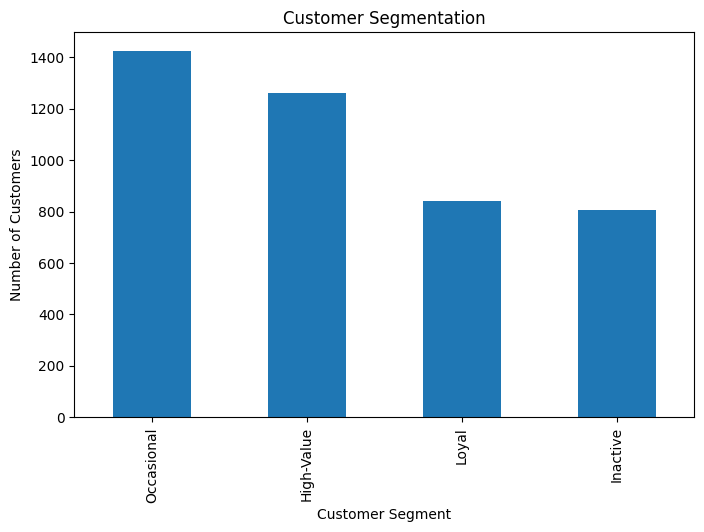

In [ ]:
#plotting customer segments
plt.figure(figsize=(8,5))

segment_count.plot(kind="bar")

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# importing libraries for k-means clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
#selecting rfm columns for clustering
rfm_data = rfm[["Recency", "Frequency", "Monetary"]]

#scaling the rfm data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(rfm_data)

print("Data scaling completed!")

display(pd.DataFrame(scaled_data, columns=["Recency", "Frequency", "Monetary"]).head())

Data scaling completed!


,Recency,Frequency,Monetary
0,2.334574,-0.425097,8.363010
1,-0.905340,0.354417,0.251699
2,-0.175360,-0.035340,-0.027988
3,-0.735345,-0.425097,-0.032406
4,2.174578,-0.425097,-0.190812


In [ ]:
#applying k-means clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(scaled_data)

print("K-Means clustering completed!")

display(rfm.head(10))

K-Means clustering completed!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster
CustomerID,,,,,,,,,
12346.0,326,1,77183.60,1,1,4,6,Occasional,3
12347.0,2,7,4310.00,4,4,4,12,High-Value,0
12348.0,75,4,1797.24,2,3,4,9,Loyal,0
12349.0,19,1,1757.55,3,1,4,8,Loyal,0
12350.0,310,1,334.40,1,1,2,4,Inactive,1
12352.0,36,8,2506.04,3,4,4,11,High-Value,0
12353.0,204,1,89.00,1,1,1,3,Inactive,1
12354.0,232,1,1079.40,1,1,3,5,Occasional,1
12355.0,214,1,459.40,1,1,2,4,Inactive,1


In [ ]:
#checking customer cluster details
cluster_analysis = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Cluster": "count"
})

print("Customer Cluster Analysis:")
display(cluster_analysis)

Customer Cluster Analysis:


,Recency,Frequency,Monetary,Cluster
Cluster,,,,
0,43.702685,3.682711,1353.625312,3054
1,248.075914,1.552015,478.848773,1067
2,7.384615,82.538462,127187.959231,13
3,15.500000,22.333333,12690.500392,204


In [ ]:
#assigning names to customer clusters
rfm["KMeans_Segment"] = rfm["Cluster"].map({
    0: "Occasional",
    1: "Inactive",
    2: "High-Value",
    3: "Loyal"
})

print("Customer segments created successfully!")

display(rfm[["Recency", "Frequency", "Monetary", "Cluster", "KMeans_Segment"]].head(10))

Customer segments created successfully!


,Recency,Frequency,Monetary,Cluster,KMeans_Segment
CustomerID,,,,,
12346.0,326,1,77183.60,3,Loyal
12347.0,2,7,4310.00,0,Occasional
12348.0,75,4,1797.24,0,Occasional
12349.0,19,1,1757.55,0,Occasional
12350.0,310,1,334.40,1,Inactive
12352.0,36,8,2506.04,0,Occasional
12353.0,204,1,89.00,1,Inactive
12354.0,232,1,1079.40,1,Inactive
12355.0,214,1,459.40,1,Inactive


In [ ]:
#counting customers in each cluster
print(rfm["KMeans_Segment"].value_counts())

KMeans_Segment
Occasional    3054
Inactive      1067
Loyal          204
High-Value      13
Name: count, dtype: int64


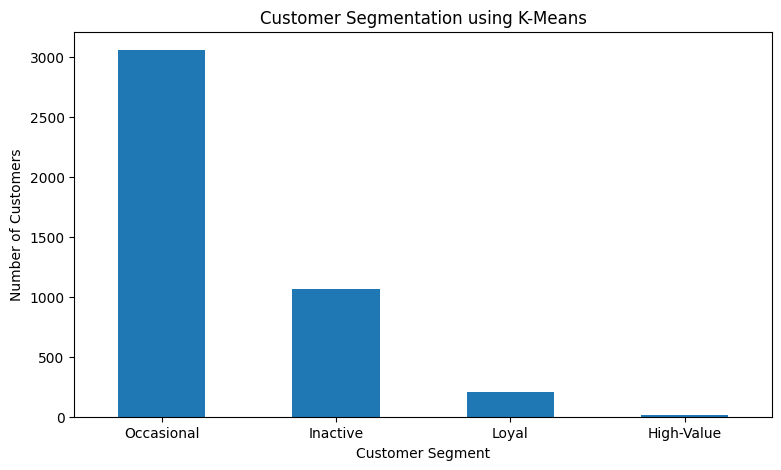

In [ ]:
#plotting customer segments
plt.figure(figsize=(9,5))

rfm["KMeans_Segment"].value_counts().plot(kind="bar")

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()